# Unsupervised Model — Complementary Product Recommendation

**Objective:**
  * Group products by similarity, create the attributes required for each product category,
   based on the EDA, using the K-Means and K-Prototypes clustering algorithms
  * Recommend alternative products based on similarity
  * Recommend complementary products based on the customer's selection
  * The goal is to infer the sale of certain products based on the organization's commercial strategies

**Dataset**:
  * The datasets are located in the TFM folder (not included in this repository)

# Datasets used

### Sales table

Sales per product

- **iddbprod** = Product Id
---


In [4]:
!pip install kmodes==0.12.2

# Common libraries


In [5]:
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder, OneHotEncoder, MinMaxScaler

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import LabelEncoder
from joblib import Parallel, delayed

from kmodes.kprototypes import KPrototypes
from sklearn.cluster import AgglomerativeClustering

import warnings
warnings.filterwarnings('ignore')

# Load data


In [7]:
#from google.colab import drive
#import os

#drive.mount('/content/drive')
base_path = 'drive/MyDrive/TFM/'

ventas      = pd.read_csv(f'{base_path}Ventas_117.txt', sep=';') #Ventas_1170.txt
categorias  = pd.read_csv(f'{base_path}Productos_Categorias.csv',sep=';')

display(ventas.head(5).style.hide(axis='index'))


iddbvtas,iddbenre,vtdbfeve,iddbprod,iddbprca,iddbprcp,mcdbdeno,iddbgrim,iddbalic,ppdbppba,ppdbppap,ppdbppli,pddbdeno,pddbcoid,pddbcoin,rrdbprod,umdbdeno,ctdbdeno,umdbsimb,addbporc,ppdbppaf,ppdbpain,ppdbpafi,umdbdein,umdbsiin
15052,1000257,2025-12-03,1746,70,258,PALMOLIVE,1,1,20598.480000,24100.220000,23070.300000,JABON PALMOLIVE LIQUIDO CORPORAL DESCANSO FLORAL X 250 ML,7891024117903,11790,11790,Caja x 12u,1.3.2.3 HIGIENE PERSONAL,Cjx12,21.000000,29161.270000,2008.350000,2430.100000,Unidades,*UN
15052,1000257,2025-12-03,1746,70,258,PALMOLIVE,1,1,20598.480000,20598.480000,20598.480000,JABON PALMOLIVE LIQUIDO CORPORAL DESCANSO FLORAL X 250 ML,7891024117903,11790,11790,Caja x 12u,1.3.2.3 HIGIENE PERSONAL,Cjx12,21.000000,24924.160000,1716.540000,2077.010000,Unidades,*UN
15052,1000257,2025-12-03,1746,70,258,PALMOLIVE,1,1,20598.480000,24100.220000,21628.400000,JABON PALMOLIVE LIQUIDO CORPORAL DESCANSO FLORAL X 250 ML,7891024117903,11790,11790,Caja x 12u,1.3.2.3 HIGIENE PERSONAL,Cjx12,21.000000,29161.270000,2008.350000,2430.100000,Unidades,*UN
15052,1000257,2025-12-03,1746,70,258,PALMOLIVE,1,1,22658.370000,22658.370000,22658.370000,JABON PALMOLIVE LIQUIDO CORPORAL DESCANSO FLORAL X 250 ML,7891024117903,11790,11790,Caja x 12u,1.3.2.3 HIGIENE PERSONAL,Cjx12,21.000000,27416.630000,1888.200000,2284.720000,Unidades,*UN
15052,1000257,2025-12-03,1746,70,258,PALMOLIVE,1,1,22658.370000,26510.290000,23791.290000,JABON PALMOLIVE LIQUIDO CORPORAL DESCANSO FLORAL X 250 ML,7891024117903,11790,11790,Caja x 12u,1.3.2.3 HIGIENE PERSONAL,Cjx12,21.000000,32077.450000,2209.190000,2673.120000,Unidades,*UN


In [8]:
columnas = {
    "iddbprcp": "Categoria",
    "iddbprca": "Subcategoria",
    "mcdbdeno": "Marca",
    "ppdbppba": "PrecioVenta"
}

# 1 — nulls
print("=== NULLS ===")
print(ventas[columnas.keys()].isnull().sum())

# 2 — data types
print("\n=== TYPES ===")
print(ventas[columnas.keys()].dtypes)

# 3 — price statistics
print("\n=== PRICE (ppdbppba) ===")
print(ventas['ppdbppba'].describe())

# 4 — categorical cardinality
print("\n=== UNIQUE VALUES ===")
for col in ['iddbprcp', 'iddbprca', 'mcdbdeno']:
    print(f"{col}: {ventas[col].nunique()} unique values")

=== NULOS ===
iddbprcp    0
iddbprca    0
mcdbdeno    0
ppdbppba    0
dtype: int64

=== TIPOS ===
iddbprcp      int64
iddbprca      int64
mcdbdeno     object
ppdbppba    float64
dtype: object

=== PRECIO (ppdbppba) ===
count    116678.000000
mean      70833.370185
std       42360.957663
min        9065.070000
25%       34387.500000
50%       61092.390000
75%       99869.490000
max      288636.480000
Name: ppdbppba, dtype: float64

=== VALORES ÚNICOS ===
iddbprcp: 2 valores únicos
iddbprca: 8 valores únicos
mcdbdeno: 7 valores únicos


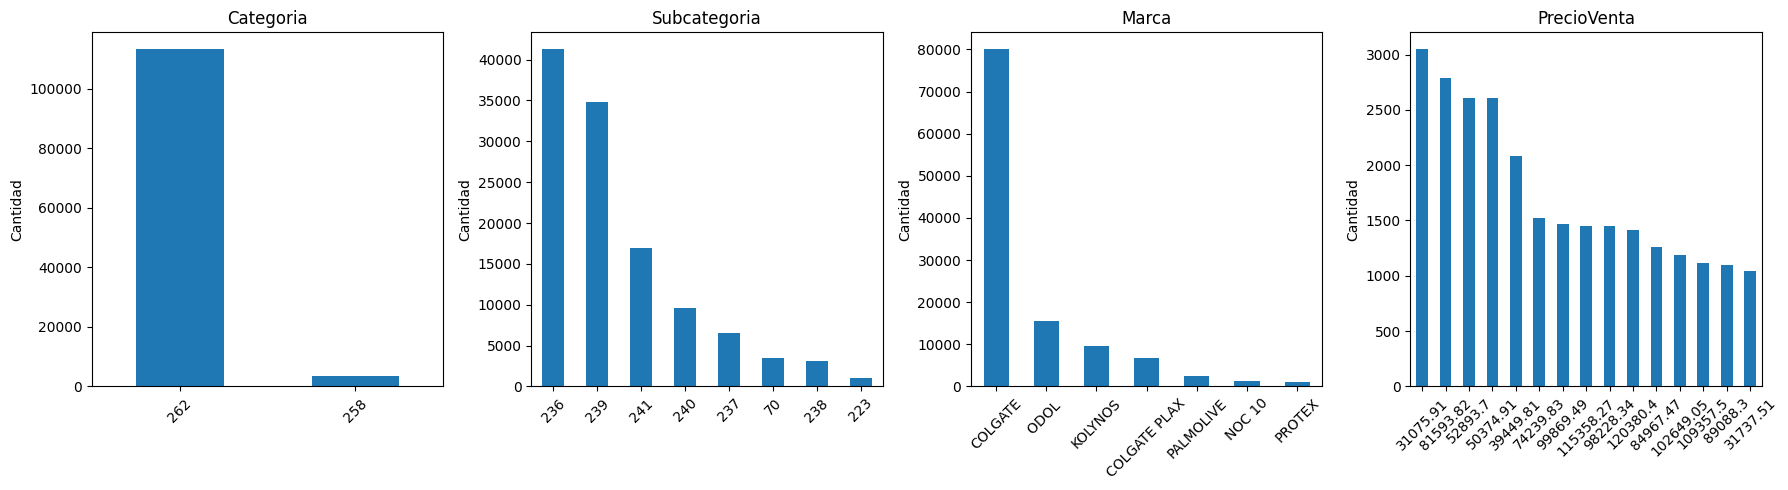

In [15]:


fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, (col, label) in enumerate(columnas.items()):
    conteo = ventas[col].fillna("NULL").value_counts().head(15)
    conteo.plot(kind="bar", ax=axes[i])
    axes[i].set_title(label)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Set up the selected product


In [16]:
# ============================================================
# 0 — target product
# ============================================================
prod_id = 117 #117, 2884, 317, 4249, 7011, 1170

prod_row = (ventas[['iddbprod', 'pddbdeno', 'mcdbdeno', 'iddbprcp', 'iddbprca']]
            .drop_duplicates()
            .query("iddbprod == @prod_id")
            .iloc[0])

productoTarget = {
    'ProductoId'  : int(prod_row['iddbprod']),
    'Producto'    : prod_row['pddbdeno'],
    'Categoria'   : int(prod_row['iddbprcp']),
    'Subcategoria': int(prod_row['iddbprca']),
    'Marca'       : prod_row['mcdbdeno']
}
print(productoTarget)

# ============================================================
# 1 — aggregate to 1 row per product, exclude target
# ============================================================
df_model = (ventas[ventas['iddbprod'] != productoTarget['ProductoId']]
    .groupby(['iddbprod', 'pddbdeno', 'iddbprcp', 'iddbprca', 'mcdbdeno'])
    .agg(precio_promedio=('ppdbppba', 'mean'),
         frecuencia=('iddbvtas', 'nunique'))
    .reset_index())

# ============================================================
# 2 — clean subcategory
# ============================================================
mapa_subcat = (ventas
    .groupby('iddbprod')['ctdbdeno']
    .first()
    .str.replace(r'^\d+(\.\d+)+\s+', '', regex=True)
    .reset_index()
    .rename(columns={'ctdbdeno': 'subcategoria'}))

df_model = df_model.merge(mapa_subcat, on='iddbprod', how='left')

# ============================================================
# 3 — normalize price
# ============================================================
scaler = StandardScaler()
df_model['precio_norm'] = scaler.fit_transform(df_model[['precio_promedio']])

# ============================================================
# 4 — split into two datasets
# ============================================================
prod_cat = productoTarget['Categoria']  # 262

# same category as the target, excluding its own subcategory
prod_similares = df_model[
    (df_model['iddbprcp'] == prod_cat) &
    (df_model['iddbprca'] != productoTarget['Subcategoria'])
].copy()

# other categories
prod_diversos = df_model[
    df_model['iddbprcp'] != prod_cat
].copy()

print(f"prod_similares: {prod_similares.shape[0]} products")
print(f"prod_diversos:  {prod_diversos.shape[0]} products")

print("\nprod_similares — subcategories:")
print(prod_similares.groupby(['iddbprca', 'subcategoria'])['iddbprod'].count()
      .reset_index()
      .rename(columns={'iddbprod': 'productos'})
      .sort_values('productos', ascending=False))

print("\nprod_diversos — subcategories:")
print(prod_diversos.groupby(['iddbprca', 'subcategoria'])['iddbprod'].count()
      .reset_index()
      .rename(columns={'iddbprod': 'productos'})
      .sort_values('productos', ascending=False))


{'ProductoId': 117, 'Producto': 'CEPILLO DENTAL COLGATE PREMIER ULTRA  CLEAN  PACK 14 X 12', 'Categoria': 262, 'Subcategoria': 236, 'Marca': 'COLGATE'}
prod_similares: 77 productos
prod_diversos:  28 productos

prod_similares — subcategorías:
   iddbprca                 subcategoria  productos
3       239         CREMA DENTAL COLGATE         36
1       237               ENJUAGUE BUCAL         20
5       241            CREMA DENTAL ODOL          8
2       238  HIGIENE BUCAL - HILO DENTAL          5
4       240         CREMA DENTAL KOLYNOS          5
0       223               COMBOS COLGATE          3

prod_diversos — subcategorías:
   iddbprca      subcategoria  productos
0        70  HIGIENE PERSONAL         28


# Build the K-Modes model


K=2 → Silhouette: 0.7170
K=3 → Silhouette: 0.7124
K=4 → Silhouette: 0.6988
K=5 → Silhouette: 0.6087
K=6 → Silhouette: 0.5970


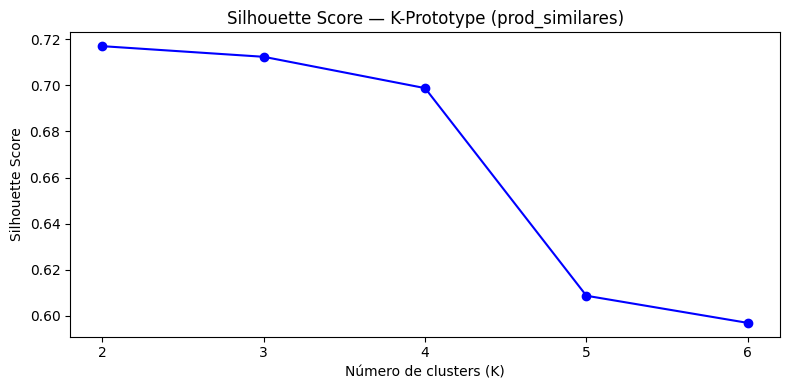

In [17]:
cat_cols = ['subcategoria', 'mcdbdeno']
num_cols = ['precio_norm', 'frecuencia']

X = prod_similares[num_cols + cat_cols].copy()
cat_idx = [X.columns.get_loc(c) for c in cat_cols]

silhouettes = []
K = range(2, 7)

for k in K:
    kproto = KPrototypes(n_clusters=k, init='Cao', n_init=5, random_state=42)
    labels = kproto.fit_predict(X, categorical=cat_idx)
    score = silhouette_score(prod_similares[num_cols], labels)
    silhouettes.append(score)
    print(f"K={k} → Silhouette: {score:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(K, silhouettes, 'bo-')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score — K-Prototype (prod_similares)')
plt.xticks(K)
plt.tight_layout()
plt.show()

# Build the Hierarchical model


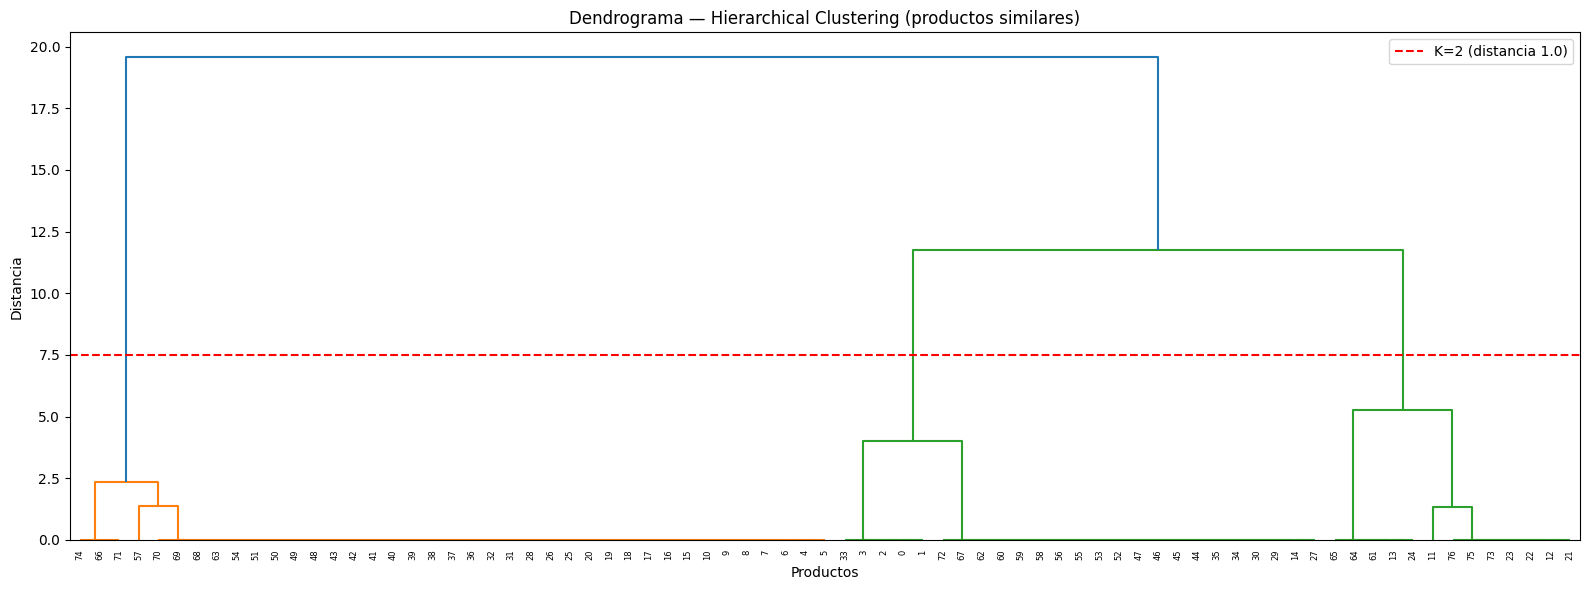

In [19]:
# encode categorical variables
le_subcat = LabelEncoder()
le_marca  = LabelEncoder()

prod_similares['subcat_enc'] = le_subcat.fit_transform(prod_similares['subcategoria'])
prod_similares['marca_enc']  = le_marca.fit_transform(prod_similares['mcdbdeno'])

X_hier = prod_similares[['subcat_enc', 'marca_enc']].values

plt.figure(figsize=(16, 6))
sch.dendrogram(sch.linkage(X_hier, method='ward'))
plt.title('Dendrogram — Hierarchical Clustering (similar products)')
plt.xlabel('Products')
plt.ylabel('Distance')
plt.axhline(y=7.5, color='red', linestyle='--', label='K=2 (distance 1.0)')
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
from kmodes.kmodes import KModes
# ============================================================
# 4 — K-Modes (categorical only) k = 3 (#117), 4, 5
# ============================================================
X_cat = prod_similares[['subcategoria', 'mcdbdeno']].copy()

km = KModes(n_clusters=3, init='Huang', n_init=5, random_state=42)
prod_similares['cluster_km'] = km.fit_predict(X_cat)

print(f"Products in prod_similares: {prod_similares.shape[0]}")
print(prod_similares.groupby(['cluster_km', 'subcategoria', 'mcdbdeno'])['iddbprod']
      .count().reset_index()
      .rename(columns={'iddbprod': 'productos'})
      .sort_values(['cluster_km', 'productos'], ascending=[True, False])
      .to_string(index=False))

Productos en prod_similares: 77
 cluster_km                subcategoria     mcdbdeno  productos
          0        CREMA DENTAL COLGATE      COLGATE         35
          0        CREMA DENTAL KOLYNOS      KOLYNOS          5
          0 HIGIENE BUCAL - HILO DENTAL      COLGATE          5
          0              COMBOS COLGATE      COLGATE          3
          0        CREMA DENTAL COLGATE COLGATE PLAX          1
          1           CREMA DENTAL ODOL        ODOL           7
          1           CREMA DENTAL ODOL       NOC 10          1
          2              ENJUAGUE BUCAL COLGATE PLAX         20


In [23]:
# ============================================================
# 5 — Hierarchical - k = 2, 3 subcategories
# ============================================================

hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
prod_similares['cluster_hc'] = hc.fit_predict(X_hier)

print(prod_similares.groupby(['cluster_hc', 'subcategoria', 'mcdbdeno'])['iddbprod']
      .count().reset_index()
      .rename(columns={'iddbprod': 'productos'})
      .sort_values(['cluster_hc', 'productos'], ascending=[True, False])
      .to_string(index=False))

 cluster_hc                subcategoria     mcdbdeno  productos
          0           CREMA DENTAL ODOL        ODOL           7
          0        CREMA DENTAL KOLYNOS      KOLYNOS          5
          0           CREMA DENTAL ODOL       NOC 10          1
          1        CREMA DENTAL COLGATE      COLGATE         35
          1              COMBOS COLGATE      COLGATE          3
          1        CREMA DENTAL COLGATE COLGATE PLAX          1
          2              ENJUAGUE BUCAL COLGATE PLAX         20
          2 HIGIENE BUCAL - HILO DENTAL      COLGATE          5


In [25]:
print("=" * 60)
print(f"RECOMMENDATIONS FOR: {productoTarget['Producto'][:50]}")
print("=" * 60)

# TOP-6 prod_similares per cluster
print("\n--- SIMILAR PRODUCTS (same category) ---")
top2_similares = (prod_similares
    .drop_duplicates(subset='iddbprod')
    .sort_values('frecuencia', ascending=False)
    .groupby('cluster_km')
    .head(2)
    [['cluster_km', 'subcategoria', 'mcdbdeno', 'pddbdeno', 'frecuencia']]
    .sort_values(['cluster_km', 'frecuencia'], ascending=[True, False]))

print(top2_similares.to_string(index=False))

RECOMENDACIONES PARA: CEPILLO DENTAL COLGATE PREMIER ULTRA  CLEAN  PACK 

--- PRODUCTOS SIMILARES (misma categoría) ---
 cluster_km         subcategoria     mcdbdeno                                                   pddbdeno  frecuencia
          0 CREMA DENTAL COLGATE      COLGATE     PASTA DENTAL COLGATE PROTECCIÓN ANTICARIES X 70 GRS.**         238
          0 CREMA DENTAL KOLYNOS      KOLYNOS           PASTA DENTAL KOLYNOS WHITE PROTECTION X 70 GRS.*         232
          1    CREMA DENTAL ODOL        ODOL                    PASTA DENTAL ODOL DOBLE EFECTO X 70 GRS.         211
          1    CREMA DENTAL ODOL        ODOL          CREMA DENTAL INFANTIL  ODOLITO  TUTTI FRUTTI X 50G         180
          2       ENJUAGUE BUCAL COLGATE PLAX ENJUAGUE BUCAL COLGATE PLAX SOFT MINT-MENTA SUAVE X 250 ML         104
          2       ENJUAGUE BUCAL COLGATE PLAX              ENJUAGUE BUCAL COLGATE PLAX  CLASICO X 250 ML          78


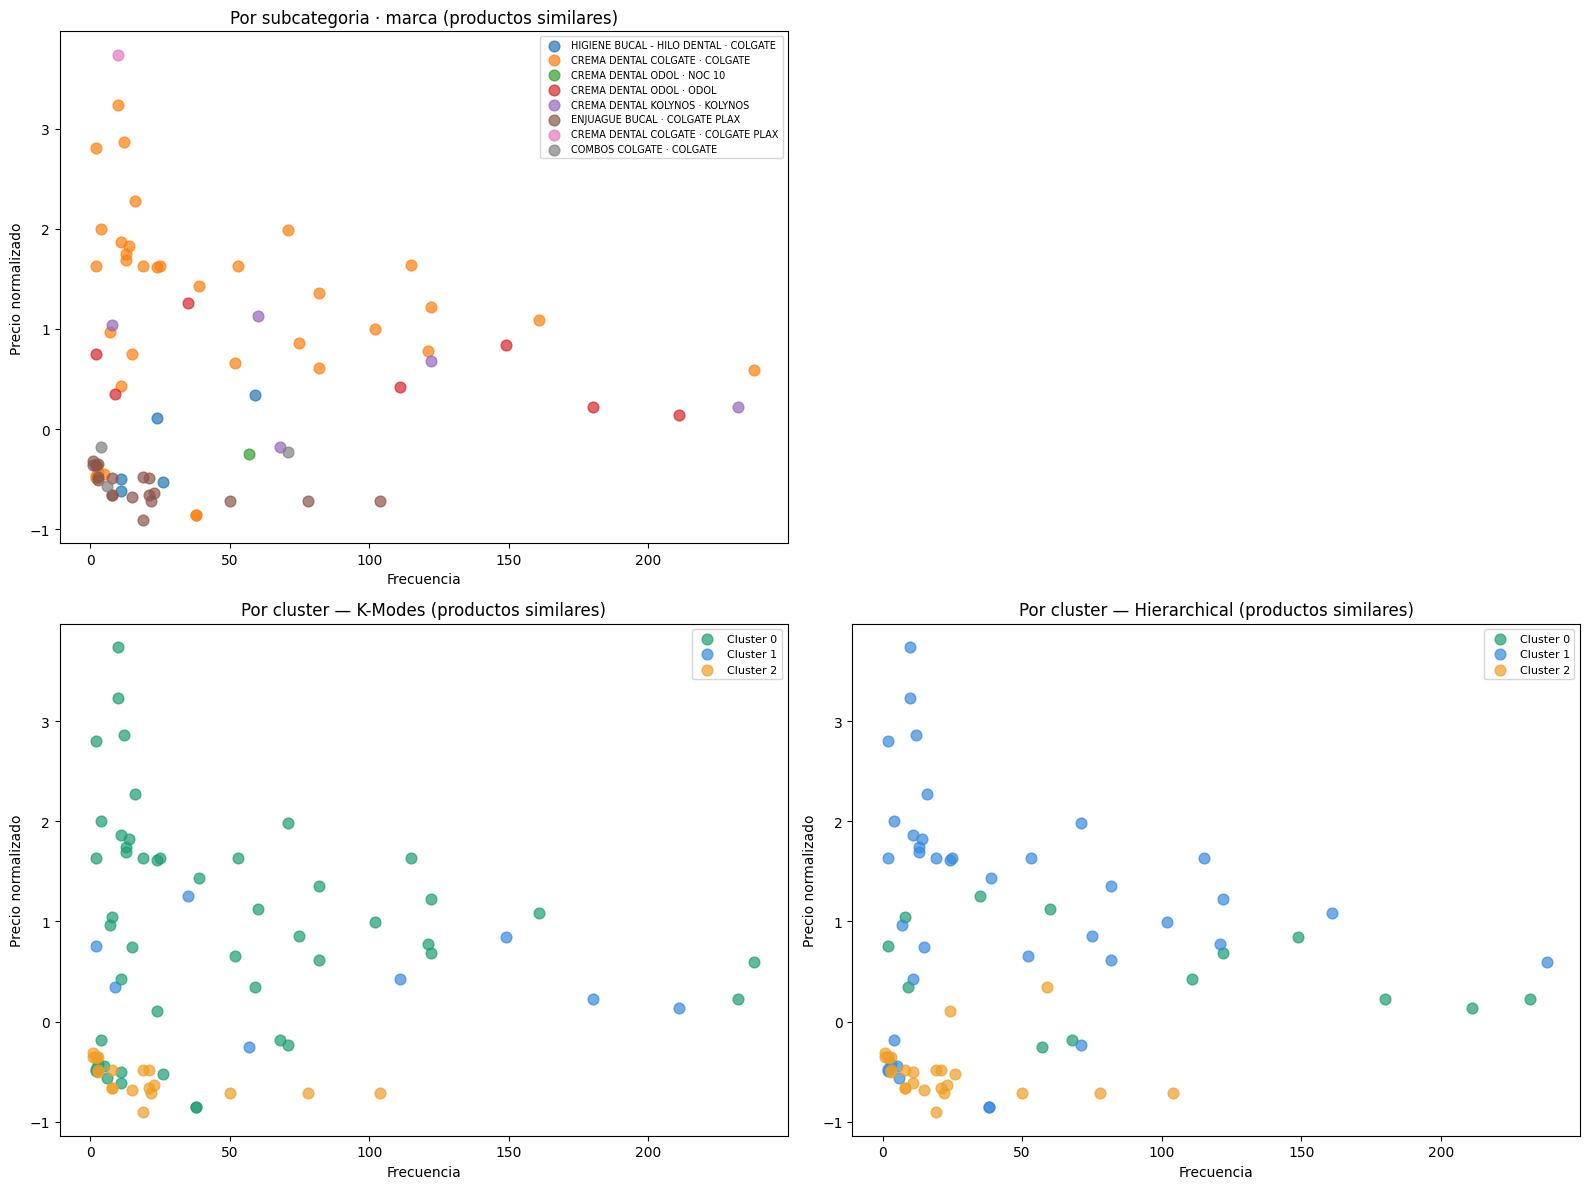

In [26]:
colores_cluster = {0: '#1D9E75', 1: '#378ADD', 2: '#EF9F27'}
fig, axes = plt.subplots(2, 2, figsize=(16, 12), squeeze=False)
# ============================================================
# ROW 1 — subcategory · brand
# ============================================================
prod_similares['subcat_marca'] = prod_similares['subcategoria'] + ' · ' + prod_similares['mcdbdeno']

for val in prod_similares['subcat_marca'].unique():
    subset = prod_similares[prod_similares['subcat_marca'] == val]
    axes[0,0].scatter(subset['frecuencia'], subset['precio_norm'],
                    label=val, s=60, alpha=0.7)
axes[0,0].set_title('By subcategory · brand (similar products)')
axes[0,0].set_xlabel('Frequency')
axes[0,0].set_ylabel('Normalized price')
axes[0,0].legend(fontsize=7, loc='upper right')

# turn off the second axis of row 1
axes[0,1].set_visible(False)

# ============================================================
# ROW 2 — left: K-Modes
# ============================================================
for cluster_id in sorted(prod_similares['cluster_km'].unique()):
    subset = prod_similares[prod_similares['cluster_km'] == cluster_id]
    axes[1,0].scatter(subset['frecuencia'], subset['precio_norm'],
                    label=f'Cluster {cluster_id}',
                    color=colores_cluster[cluster_id],
                    s=60, alpha=0.7)
axes[1,0].set_title('By cluster — K-Modes (similar products)')
axes[1,0].set_xlabel('Frequency')
axes[1,0].set_ylabel('Normalized price')
axes[1,0].legend(fontsize=8)

# ============================================================
# ROW 2 — right: Hierarchical
# ============================================================
for cluster_id in sorted(prod_similares['cluster_hc'].unique()):
    subset = prod_similares[prod_similares['cluster_hc'] == cluster_id]
    axes[1,1].scatter(subset['frecuencia'], subset['precio_norm'],
                    label=f'Cluster {cluster_id}',
                    color=colores_cluster[cluster_id],
                    s=60, alpha=0.7)
axes[1,1].set_title('By cluster — Hierarchical (similar products)')
axes[1,1].set_xlabel('Frequency')
axes[1,1].set_ylabel('Normalized price')
axes[1,1].legend(fontsize=8)

plt.tight_layout()
plt.show()


Varianza explicada: 100.0%


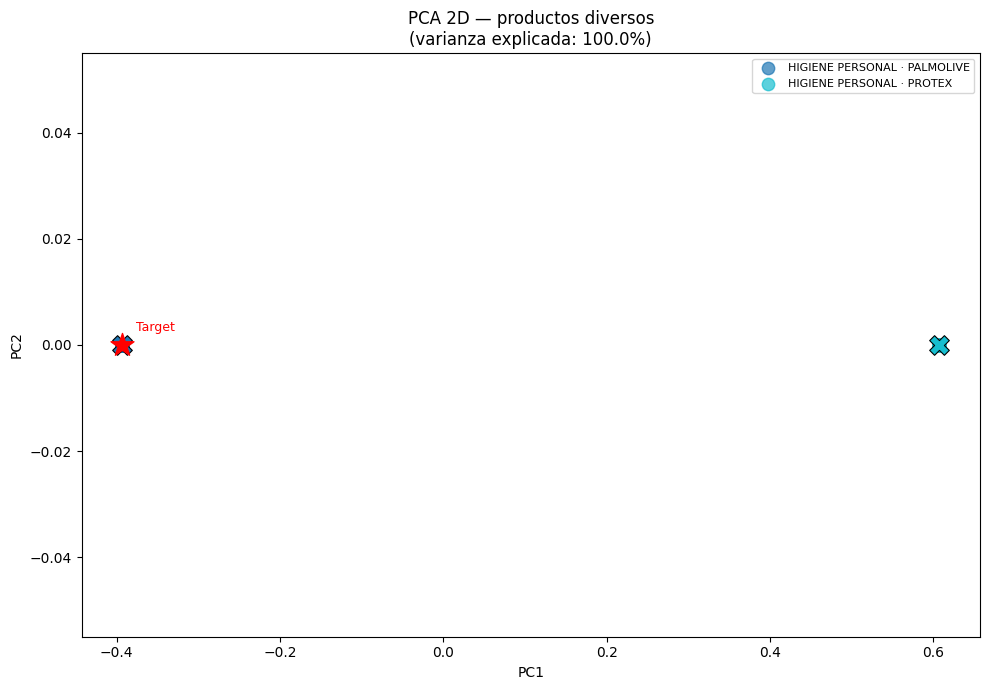

In [27]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import numpy as np
import re

# encode prod_diversos
le_subcat2 = LabelEncoder()
le_marca2  = LabelEncoder()

prod_diversos['subcat_enc'] = le_subcat2.fit_transform(prod_diversos['subcategoria'])
prod_diversos['marca_enc']  = le_marca2.fit_transform(prod_diversos['mcdbdeno'])

X_pca2 = prod_diversos[['subcat_enc', 'marca_enc']].values

pca2 = PCA(n_components=2)
coords2 = pca2.fit_transform(X_pca2)
prod_diversos['pca_x'] = coords2[:, 0]
prod_diversos['pca_y'] = coords2[:, 1]

print(f"Explained variance: {pca2.explained_variance_ratio_.sum()*100:.1f}%")

# target
cat_target_norm = re.sub(r'^\d+(\.\d+)+\s+', '',
    categorias[categorias['iddbprca'] == productoTarget['Subcategoria']]['ctdbdeno'].values[0])

subcat_target = le_subcat2.transform([cat_target_norm])[0] if cat_target_norm in le_subcat2.classes_ else 0
marca_target  = le_marca2.transform([productoTarget['Marca']])[0] if productoTarget['Marca'] in le_marca2.classes_ else 0

punto_target = pca2.transform([[subcat_target, marca_target]])

# plot — color by subcategory · brand
prod_diversos['subcat_marca'] = prod_diversos['subcategoria'] + ' · ' + prod_diversos['mcdbdeno']
colores2 = plt.cm.tab10(np.linspace(0, 1, prod_diversos['subcat_marca'].nunique()))

fig, ax = plt.subplots(figsize=(10, 7))

for i, val in enumerate(sorted(prod_diversos['subcat_marca'].unique())):
    subset = prod_diversos[prod_diversos['subcat_marca'] == val]
    ax.scatter(subset['pca_x'], subset['pca_y'],
               label=val, color=colores2[i], s=80, alpha=0.7)
    cx, cy = subset['pca_x'].mean(), subset['pca_y'].mean()
    ax.scatter(cx, cy, color=colores2[i], s=200, marker='X',
               edgecolors='black', linewidths=0.8)

ax.scatter(punto_target[0, 0], punto_target[0, 1],
           color='red', s=300, marker='*', zorder=5)
ax.annotate('Target',
            xy=(punto_target[0, 0], punto_target[0, 1]),
            xytext=(10, 10), textcoords='offset points',
            fontsize=9, color='red')

ax.set_title(f'PCA 2D — diverse products\n(explained variance: {pca2.explained_variance_ratio_.sum()*100:.1f}%)')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

# Outliers

In [28]:
outliers = (prod_diversos
    .drop_duplicates(subset='iddbprod')
    .sort_values('frecuencia', ascending=False)
    [['iddbprcp', 'iddbprca', 'subcategoria', 'mcdbdeno', 'pddbdeno', 'frecuencia']])

print(f"Outlier products: {len(outliers)}")
print(outliers.to_string(index=False))

Productos outliers: 28
 iddbprcp  iddbprca     subcategoria  mcdbdeno                                                        pddbdeno  frecuencia
      258        70 HIGIENE PERSONAL PALMOLIVE              JABON PALMOLIVE NATURALS FRAMBUESA Y MORA X 85 GR.          23
      258        70 HIGIENE PERSONAL PALMOLIVE            JABON PALMOLIVE NATURALS ALOE VERA Y OLIVA  X 85 GR.          23
      258        70 HIGIENE PERSONAL PALMOLIVE                        JABON PALMOLIVE NATURALS KARITÉ X 85 GR.          17
      258        70 HIGIENE PERSONAL PALMOLIVE      JABON PALMOLIVE NATURALS JAZMIN Y MANTECA DE CACAO X 85 G.          17
      258        70 HIGIENE PERSONAL PALMOLIVE          JABON PALMOLIVE LIQUIDO LUMINOUS OIL AGUACATE X 250 ML           8
      258        70 HIGIENE PERSONAL PALMOLIVE             JABON PALMOLIVE LIQUIDO CORPORAL NUTRIMILK X 250 ML           7
      258        70 HIGIENE PERSONAL    PROTEX           JABON PROTEX LIQUIDO MANOS BALANCE  REPUESTO X 200 ML      

In [30]:
# ============================================================
#   Top-3 Products
#   Only 1 subcategory in prod_diversos → top-3 by brand directly
#   Several subcategories → use K-Modes clusters and top-3 per cluster
# ============================================================

print("=== TOP-3 prod_diversos by subcategory and brand ===")
print(prod_diversos
      .drop_duplicates(subset='iddbprod')
      .sort_values('frecuencia', ascending=False)
      .groupby(['iddbprca', 'subcategoria', 'mcdbdeno'])
      .head(3)
      [['iddbprca', 'subcategoria', 'mcdbdeno', 'pddbdeno', 'frecuencia']]
      .sort_values(['iddbprca', 'mcdbdeno', 'frecuencia'], ascending=[True, True, False])
      .to_string(index=False))

=== TOP-3 prod_diversos por subcategoría y marca ===
 iddbprca     subcategoria  mcdbdeno                                                    pddbdeno  frecuencia
       70 HIGIENE PERSONAL PALMOLIVE          JABON PALMOLIVE NATURALS FRAMBUESA Y MORA X 85 GR.          23
       70 HIGIENE PERSONAL PALMOLIVE        JABON PALMOLIVE NATURALS ALOE VERA Y OLIVA  X 85 GR.          23
       70 HIGIENE PERSONAL PALMOLIVE                    JABON PALMOLIVE NATURALS KARITÉ X 85 GR.          17
       70 HIGIENE PERSONAL    PROTEX       JABON PROTEX LIQUIDO MANOS BALANCE  REPUESTO X 200 ML           6
       70 HIGIENE PERSONAL    PROTEX JABON PROTEX BARRA AVENA + PREBIÓTICOS PAQUETE X 3 X 90GRS.           6
       70 HIGIENE PERSONAL    PROTEX             JABON PROTEX CARBON DETOX PAQUETE X 3 X 90G C/U           5


In [31]:
# @title
# K-Modes over prod_diversos
le_subcat2 = LabelEncoder()
le_marca2  = LabelEncoder()

prod_diversos['subcat_enc'] = le_subcat2.fit_transform(prod_diversos['subcategoria'])
prod_diversos['marca_enc']  = le_marca2.fit_transform(prod_diversos['mcdbdeno'])

X_cat2 = prod_diversos[['subcategoria', 'mcdbdeno']].copy()

km2 = KModes(n_clusters=4, init='Huang', n_init=5, random_state=42)
prod_diversos['cluster_km'] = km2.fit_predict(X_cat2)

print(prod_diversos.groupby(['cluster_km', 'subcategoria', 'mcdbdeno'])['iddbprod']
      .count().reset_index()
      .rename(columns={'iddbprod': 'productos'})
      .sort_values(['cluster_km', 'productos'], ascending=[True, False])
      .to_string(index=False))

 cluster_km     subcategoria  mcdbdeno  productos
          0 HIGIENE PERSONAL    PROTEX         11
          1 HIGIENE PERSONAL PALMOLIVE         17


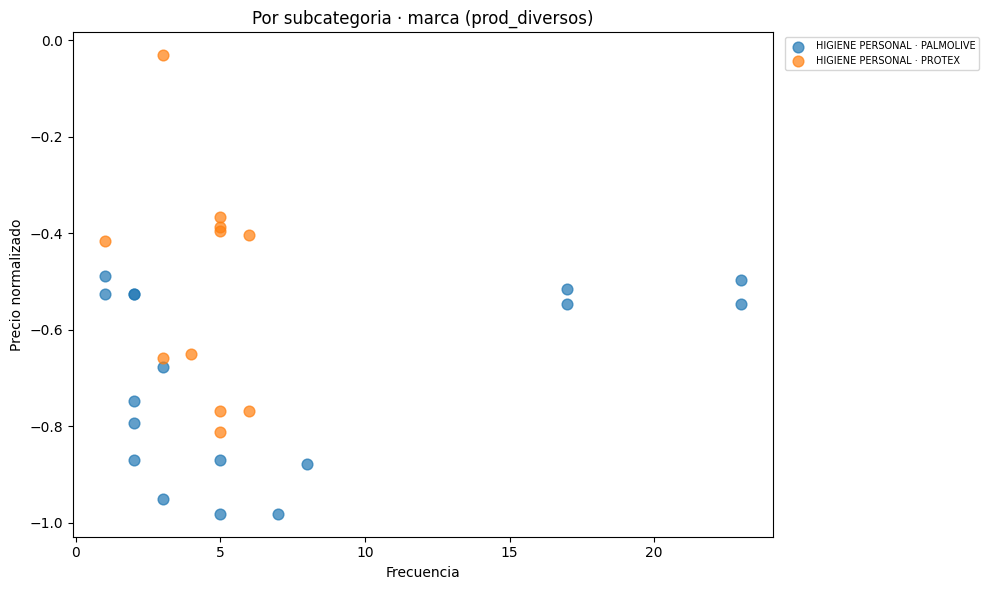

In [32]:
# @title
fig, ax = plt.subplots(figsize=(10, 6))

prod_diversos['subcat_marca'] = prod_diversos['subcategoria'] + ' · ' + prod_diversos['mcdbdeno']

for val in prod_diversos['subcat_marca'].unique():
    subset = prod_diversos[prod_diversos['subcat_marca'] == val]
    ax.scatter(subset['frecuencia'], subset['precio_norm'],
               label=val, s=60, alpha=0.7)

ax.set_title('By subcategory · brand (prod_diversos)')
ax.set_xlabel('Frequency')
ax.set_ylabel('Normalized price')
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

Varianza explicada: 100.0%


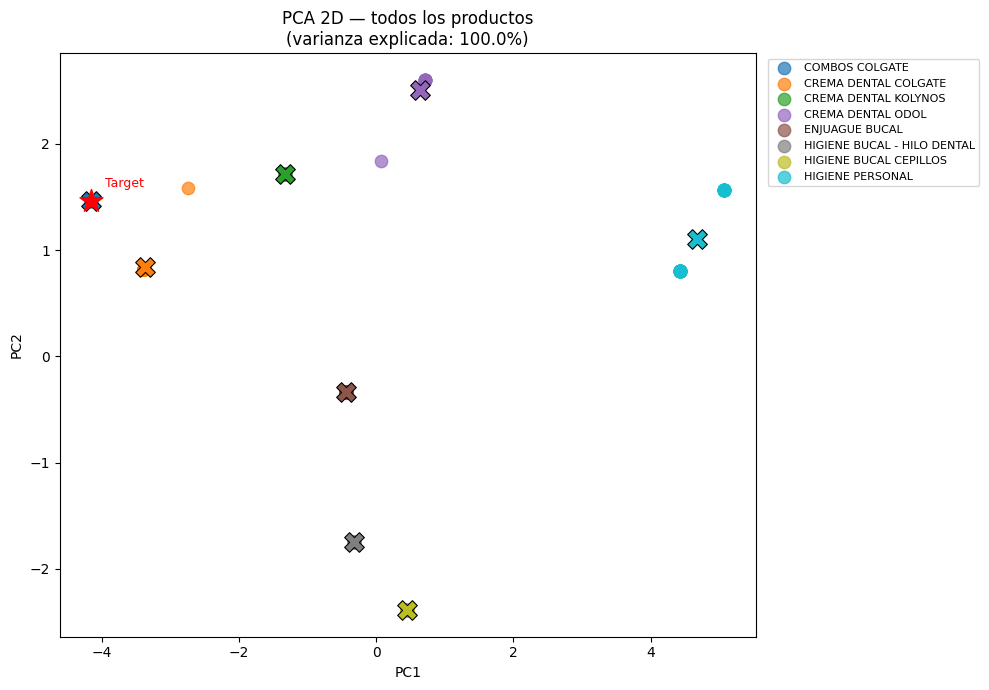

In [34]:
# @title
# PCA — full df_model (all products)
le_subcat = LabelEncoder()
le_marca  = LabelEncoder()

df_pca = df_model.copy()
df_pca['subcat_enc'] = le_subcat.fit_transform(df_pca['subcategoria'])
df_pca['marca_enc']  = le_marca.fit_transform(df_pca['mcdbdeno'])

# categorical only, to avoid frequency/price distortion
X_pca = df_pca[['subcat_enc', 'marca_enc']].values

pca = PCA(n_components=2)
coords = pca.fit_transform(X_pca)
df_pca['pca_x'] = coords[:, 0]
df_pca['pca_y'] = coords[:, 1]

print(f"Explained variance: {pca.explained_variance_ratio_.sum()*100:.1f}%")

# target
cat_target_norm = re.sub(r'^\d+(\.\d+)+\s+', '',
    categorias[categorias['iddbprca'] == productoTarget['Subcategoria']]['ctdbdeno'].values[0])

subcat_target = le_subcat.transform([cat_target_norm])[0] if cat_target_norm in le_subcat.classes_ else 0
marca_target  = le_marca.transform([productoTarget['Marca']])[0] if productoTarget['Marca'] in le_marca.classes_ else 0

punto_target = pca.transform([[subcat_target, marca_target]])

# plot — color by subcategory
fig, ax = plt.subplots(figsize=(10, 7))
colores_all = plt.cm.tab10(np.linspace(0, 1, df_pca['subcategoria'].nunique()))

for i, subcat in enumerate(sorted(df_pca['subcategoria'].unique())):
    subset = df_pca[df_pca['subcategoria'] == subcat]
    ax.scatter(subset['pca_x'], subset['pca_y'],
               label=subcat, color=colores_all[i], s=80, alpha=0.7)
    cx, cy = subset['pca_x'].mean(), subset['pca_y'].mean()
    ax.scatter(cx, cy, color=colores_all[i], s=200, marker='X',
               edgecolors='black', linewidths=0.8)

# target — no label
ax.scatter(punto_target[0, 0], punto_target[0, 1],
           color='red', s=300, marker='*', zorder=5)
ax.annotate('Target',
            xy=(punto_target[0, 0], punto_target[0, 1]),
            xytext=(10, 10), textcoords='offset points',
            fontsize=9, color='red')

ax.set_title(f'PCA 2D — all products\n(explained variance: {pca.explained_variance_ratio_.sum()*100:.1f}%)')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

In [36]:
# @title
# ============================================================
# TOP-3 prod_diversos — 3 best sellers of each subcategory
# ============================================================
n_subcats = prod_diversos['subcategoria'].nunique()
print(f"Subcategories in prod_diversos: {n_subcats}")

if n_subcats == 1:
    print("\n--- 1 subcategory — TOP-3 by Brand ---")
    top3_diversos = (prod_diversos
        .drop_duplicates(subset='iddbprod')
        .sort_values('frecuencia', ascending=False)
        .groupby('mcdbdeno')
        .head(3)
        [['subcategoria', 'mcdbdeno', 'pddbdeno', 'frecuencia']]
        .sort_values(['mcdbdeno', 'frecuencia'], ascending=[True, False]))
else:
    print("\n--- Several subcategories — TOP-3 by Subcategory · Brand ---")
    top3_diversos = (prod_diversos
        .drop_duplicates(subset='iddbprod')
        .sort_values('frecuencia', ascending=False)
        .groupby(['iddbprca', 'subcategoria', 'mcdbdeno'])
        .head(3)
        [['iddbprca', 'subcategoria', 'mcdbdeno', 'pddbdeno', 'frecuencia']]
        .sort_values(['iddbprca', 'mcdbdeno', 'frecuencia'], ascending=[True, True, False]))

print(top3_diversos.to_string(index=False))

Subcategorías en prod_diversos: 1

--- 1 subcategoría — TOP-3 por Marca ---
    subcategoria  mcdbdeno                                                    pddbdeno  frecuencia
HIGIENE PERSONAL PALMOLIVE          JABON PALMOLIVE NATURALS FRAMBUESA Y MORA X 85 GR.          23
HIGIENE PERSONAL PALMOLIVE        JABON PALMOLIVE NATURALS ALOE VERA Y OLIVA  X 85 GR.          23
HIGIENE PERSONAL PALMOLIVE                    JABON PALMOLIVE NATURALS KARITÉ X 85 GR.          17
HIGIENE PERSONAL    PROTEX       JABON PROTEX LIQUIDO MANOS BALANCE  REPUESTO X 200 ML           6
HIGIENE PERSONAL    PROTEX JABON PROTEX BARRA AVENA + PREBIÓTICOS PAQUETE X 3 X 90GRS.           6
HIGIENE PERSONAL    PROTEX             JABON PROTEX CARBON DETOX PAQUETE X 3 X 90G C/U           5


# Metrics


In [40]:
print("K-Modes:")
print(prod_similares['cluster_km'].value_counts().sort_index())

print("\nHierarchical:")
print(prod_similares['cluster_hc'].value_counts().sort_index())

K-Modes:
cluster_km
0    49
1     8
2    20
Name: count, dtype: int64

Hierarchical:
cluster_hc
0    13
1    39
2    25
Name: count, dtype: int64


In [38]:
#k = 3,4,5

from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import numpy as np

resultados = []

# prod_similares
X_eval_sim = prod_similares[['subcat_enc', 'marca_enc']].values

for nombre, col_cluster in [('K-Modes (K=3)', 'cluster_km'), ('Hierarchical (K=2)', 'cluster_hc')]:
    labels = prod_similares[col_cluster].values
    resultados.append({
        'Dataset'           : 'prod_similares',
        'Modelo'            : nombre,
        'Silhouette'        : round(silhouette_score(X_eval_sim, labels), 4),
        'Davies-Bouldin'    : round(davies_bouldin_score(X_eval_sim, labels), 4),
        'Calinski-Harabasz' : round(calinski_harabasz_score(X_eval_sim, labels), 4),
        'Inercia'           : round(sum(
            np.sum((X_eval_sim[labels == c] - X_eval_sim[labels == c].mean(axis=0))**2)
            for c in np.unique(labels)), 2)
    })

df_eval = pd.DataFrame(resultados).set_index(['Dataset', 'Modelo'])
df_eval


Silhouette  Davies-Bouldin  \
Dataset        Modelo                                           
prod_similares K-Modes (K=3)           0.6916          0.3589   
               Hierarchical (K=2)      0.8509          0.4624   

                                   Calinski-Harabasz  Inercia  
Dataset        Modelo                                          
prod_similares K-Modes (K=3)                 72.0145    97.53  
               Hierarchical (K=2)           364.0126    26.51